# Exploratory analysis: Airbnb in Istanbul

Run `python scripts/download_data.py` and `python scripts/preprocess.py` first. Under every output, write in your own words what you found (not only what was plotted).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'

raw = pd.read_csv(RAW / 'listings.csv.gz', low_memory=False)
listings = pd.read_csv(PROCESSED / 'listings_clean.csv', parse_dates=['first_review', 'last_review', 'last_scraped'])
monthly = pd.read_csv(PROCESSED / 'monthly_reviews_district.csv', parse_dates=['month'])
districts = pd.read_csv(PROCESSED / 'district_summary.csv')

## 1. First contact
Shape, column types, a random sample, missing values, duplicates, identifiers.

In [2]:
print(raw.shape)
raw.dtypes.value_counts()

(27232, 90)


float64    31
int64      30
str        29
Name: count, dtype: int64

In [3]:
raw.sample(5, random_state=421)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
12140,969416994295479925,https://www.airbnb.com/rooms/969416994295479925,20260925130056,2026-09-29,previous scrape,kanlıca sahil yalı dairesi,Bring the whole family to this great place wit...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,534647814,...,NaN,NaN,NaN,NaN,NaN,2,2,0,0,NaN
19480,1421830516884017772,https://www.airbnb.com/rooms/1421830516884017772,20260925130056,2026-09-28,NaN,Comfort Quadruple Family Room,This spacious room has 1 double bed + 2 single...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,10744883,...,NaN,NaN,NaN,34-0322,NaN,16,0,12,4,NaN
17352,1293380487039079285,https://www.airbnb.com/rooms/1293380487039079285,20260925130056,2026-09-28,NaN,Antalya 03 / Executive 2+1 Room,The accommodation price includes all year roun...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,583214894,...,5.00,5.00,5.0,2024-34-1262,NaN,17,17,0,0,0.15
18799,1384126389442904748,https://www.airbnb.com/rooms/1384126389442904748,20260925130056,2026-09-29,previous scrape,En az 101 gün kiralık daire,Enjoy a simple and comfortable stay in this ce...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,686108558,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
13073,1016479372722064673,https://www.airbnb.com/rooms/1016479372722064673,20260925130056,2026-09-28,NaN,"Stylish 1BR Apt. in Beyoğlu; w/ Pool, Spa, Par...","Located in Beyoğlu, the heart of Istanbul. Rig...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,96460850,...,4.87,4.43,4.7,34-1096-1,NaN,347,347,0,0,0.88


In [4]:
missing = listings.isna().mean().sort_values(ascending=False)
missing[missing > 0].round(3)

last_review             0.355
review_scores_rating    0.355
first_review            0.355
price                   0.098
bedrooms                0.001
dtype: float64

In [5]:
print('duplicate listing ids in raw file:', raw['id'].duplicated().sum())
print('unique hosts:', listings['host_id'].nunique(), '| listings:', len(listings))

duplicate listing ids in raw file: 0
unique hosts: 9967 | listings: 27232


_Write here: what are the identifiers, which columns are missing most and what we decided (see data/README.md)._

## 2. One variable at a time

In [6]:
listings['price'].describe(percentiles=[.05, .25, .5, .75, .95, .995]).round(0)

count      24553.0
mean        6022.0
std        38240.0
min           79.0
5%           835.0
25%         2303.0
50%         3710.0
75%         6075.0
95%        13933.0
99.5%      55730.0
max      4989148.0
Name: price, dtype: float64

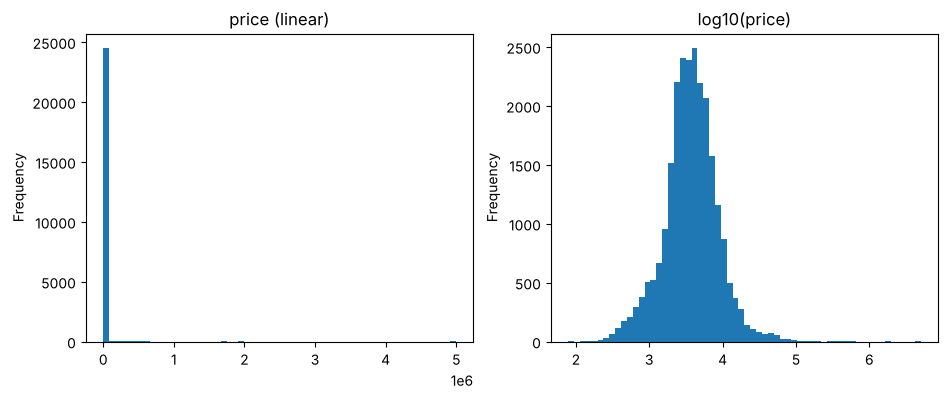

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
listings['price'].plot.hist(bins=60, ax=ax[0], title='price (linear)')
listings['price'].dropna().pipe(lambda s: s[s > 0]).apply(__import__('numpy').log10).plot.hist(bins=60, ax=ax[1], title='log10(price)')
plt.show()

In [8]:
listings['room_type'].value_counts(normalize=True).round(3)

room_type
Entire home/apt    0.674
Private room       0.310
Hotel room         0.010
Shared room        0.006
Name: proportion, dtype: float64

In [9]:
listings['district'].value_counts().head(15)

district
Beyoglu         7447
Fatih           4135
Sisli           3722
Kadikoy         1948
Besiktas        1457
Esenyurt         944
Bahcelievler     783
Uskudar          590
Bagcilar         473
Kagithane        460
Sile             421
Atasehir         409
Umraniye         332
Maltepe          330
Pendik           320
Name: count, dtype: int64

In [10]:
listings[['accommodates', 'minimum_nights', 'availability_365', 'number_of_reviews', 'review_scores_rating']].describe().round(1)

,accommodates,minimum_nights,availability_365,number_of_reviews,review_scores_rating
count,27232.0,27232.0,27232.0,27232.0,17571.0
mean,3.5,40.8,287.0,22.9,4.6
std,2.2,58.3,106.8,50.4,0.7
min,1.0,1.0,0.0,0.0,0.0
25%,2.0,1.0,260.0,0.0,4.5
50%,3.0,2.0,346.0,3.0,4.8
75%,4.0,100.0,364.0,22.0,5.0
max,16.0,1000.0,365.0,1862.0,5.0


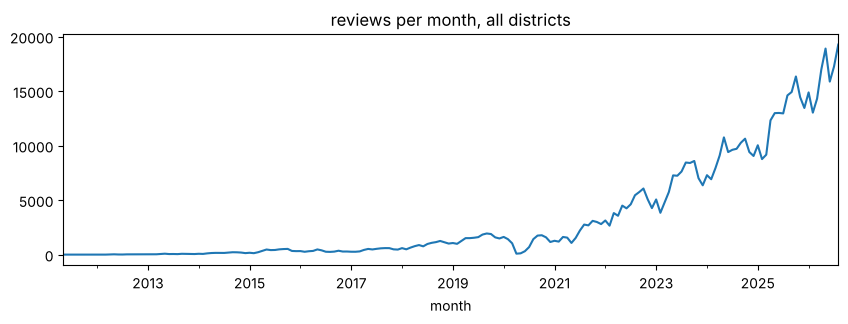

In [11]:
monthly.set_index('month').sum(axis=1).plot(figsize=(10, 3), title='reviews per month, all districts')
plt.show()

_Write here: shape of the price distribution, the most common room type, the busiest districts, the trend in reviews._

## 3. Relationships

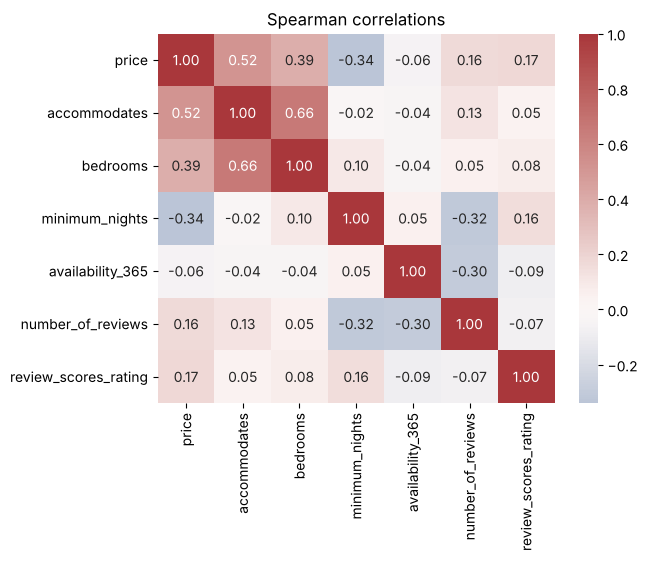

In [12]:
num = listings[['price', 'accommodates', 'bedrooms', 'minimum_nights', 'availability_365', 'number_of_reviews', 'review_scores_rating']]
sns.heatmap(num.corr(method='spearman'), annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Spearman correlations')
plt.show()

In [13]:
listings.groupby('room_type')['price'].median().sort_values()

room_type
Shared room        2399.2
Private room       2500.0
Entire home/apt    4400.0
Hotel room         6465.0
Name: price, dtype: float64

In [14]:
pd.crosstab(listings['district'], listings['room_type'], normalize='index').loc[listings['district'].value_counts().head(10).index].round(2)

room_type,Entire home/apt,Hotel room,Private room,Shared room
district,,,,
Beyoglu,0.76,0.00,0.23,0.01
Fatih,0.51,0.02,0.46,0.01
Sisli,0.74,0.01,0.25,0.00
Kadikoy,0.65,0.01,0.35,0.00
Besiktas,0.67,0.00,0.33,0.00
Esenyurt,0.80,0.01,0.18,0.00
Bahcelievler,0.88,0.00,0.12,0.00
Uskudar,0.52,0.00,0.48,0.01
Bagcilar,0.89,0.06,0.05,0.00


In [15]:
listings.groupby('district')['price'].median().loc[listings['district'].value_counts().head(10).index].round(0)

district
Beyoglu         4221.0
Fatih           3400.0
Sisli           4458.0
Kadikoy         3020.0
Besiktas        3913.0
Esenyurt        2629.0
Bahcelievler    3568.0
Uskudar         3873.0
Bagcilar        4511.0
Kagithane       2334.0
Name: price, dtype: float64

In [16]:
print('Spearman, district listings vs median price:', districts['listings'].corr(districts['median_price'], method='spearman').round(2))
print('Spearman, district listings vs share of multi-listing hosts:', districts['listings'].corr(districts['share_multi_listing_host'], method='spearman').round(2))

Spearman, district listings vs median price: 0.35
Spearman, district listings vs share of multi-listing hosts: 0.65


In [17]:
districts.sort_values('median_price', ascending=False).head(10)

,district,listings,share_entire_home,share_multi_listing_host,reviews_total,median_price,priced_listings
28,Silivri,100,0.840000,0.430000,320,6334.760,72
20,Adalar,252,0.503968,0.718254,9057,6000.000,213
26,Zeytinburnu,163,0.791411,0.650307,2436,5712.500,152
10,Sile,421,0.631829,0.726841,5395,5000.000,371
21,Sariyer,214,0.626168,0.514019,1989,4800.000,176
8,Bagcilar,473,0.885835,0.784355,3236,4457.830,423
2,Sisli,3722,0.735357,0.771091,44957,4444.000,3317
0,Beyoglu,7447,0.760440,0.886263,296268,4208.000,6903
33,Bayrampasa,41,0.756098,0.585366,134,4180.000,35
22,Beylikduzu,194,0.907216,0.510309,1232,4137.655,176


_Write here: which relationships are strong, which are weak, and what that means for our three questions._